In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.metrics import mean_absolute_error, r2_score

Подключены: pandas и numpy для загрузки и обработки данных, matplotlib и seaborn для визуализации, а из sklearn — инструменты для разделения выборки, масштабирования признаков

## Загрузка и первичный анализ. Предобработка данных

In [4]:
df = pd.read_csv('used_car_price_dataset_extended.csv')

df = df.drop(['engine_cc', 'color', 'insurance_valid'], axis=1)

df['price_usd'] = df['price_usd'].astype(float)
df['mileage_kmpl'] = df['mileage_kmpl'].astype(float)

print(f"Размер таблицы: {df.shape[0]} автомобилей и {df.shape[1]} параметров")

accident_stats = df.groupby('accidents_reported')[['make_year', 'mileage_kmpl', 'price_usd']].median()
print('\nМедианный год выпуска, топливная эффективность (км/л) и цена ($) в зависимости от количества аварий:\n', accident_stats)

df.head(3)

Размер таблицы: 10000 автомобилей и 9 параметров

Медианный год выпуска, топливная эффективность (км/л) и цена ($) в зависимости от количества аварий:
                     make_year  mileage_kmpl  price_usd
accidents_reported                                    
0                      2009.0        18.030   6973.210
1                      2009.0        17.900   6930.640
2                      2009.0        18.030   6974.500
3                      2009.0        17.380   6577.490
4                      2011.5        18.005   8607.200
5                      2019.0        17.335   7291.135


,make_year,mileage_kmpl,fuel_type,owner_count,price_usd,brand,transmission,service_history,accidents_reported
0,2001,8.17,Petrol,4,8587.64,Chevrolet,Manual,NaN,0
1,2014,17.59,Petrol,4,5943.50,Honda,Manual,NaN,0
2,2023,18.09,Diesel,5,9273.58,BMW,Automatic,Full,1


Загрузили датасет и удалили три столбца: 'engine_cc', 'color' и 'insurance_valid'. Посчитали медианные значения года выпуска, пробега и цены в зависимости от количества аварий. Чем больше аварий, тем ниже цена.

## Кодирование и масштабирование 

In [6]:
df = pd.get_dummies(df, drop_first=True)

X = df.drop('price_usd', axis=1)
y = df['price_usd']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

number_cols = ['make_year', 'mileage_kmpl', 'owner_count', 'accidents_reported']
scaler = StandardScaler()
X_train[number_cols] = scaler.fit_transform(X_train[number_cols])
X_test[number_cols] = scaler.transform(X_test[number_cols])

X_train.head(3)


,make_year,mileage_kmpl,owner_count,accidents_reported,fuel_type_Electric,fuel_type_Petrol,brand_Chevrolet,brand_Ford,brand_Honda,brand_Hyundai,brand_Kia,brand_Nissan,brand_Tesla,brand_Toyota,brand_Volkswagen,transmission_Manual,service_history_Partial
9254,-0.860884,-1.644253,-0.705460,-0.703197,False,False,False,False,False,True,False,False,False,False,False,True,True
1561,-0.622453,-0.368146,-0.000793,-0.703197,False,False,False,False,False,True,False,False,False,False,False,True,False
1670,-0.503238,-1.482746,-0.705460,-0.703197,False,False,False,True,False,False,False,False,False,False,False,True,False


Текстовые признаки перевели в числа (через get_dummies), а цену выделили в целевую переменную y.

## Поиск оптимального числа соседей (k)

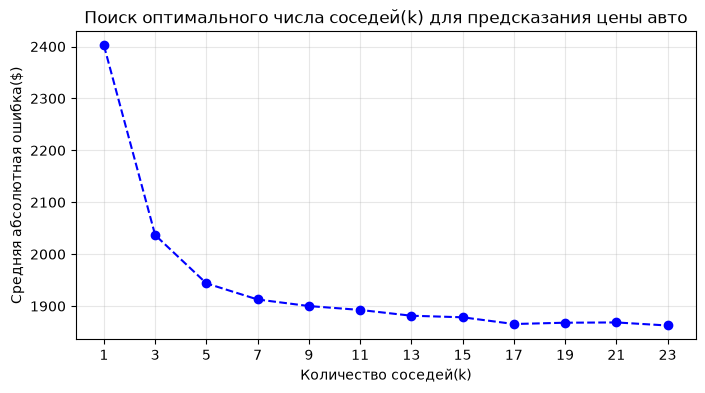

In [7]:
errors = []
k_values = range(1, 25, 2)

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    errors.append(mean_absolute_error(y_test, y_pred))

plt.figure(figsize=(8,4))
plt.plot(k_values, errors, marker="o", linestyle="dashed", color="blue")
plt.title("Поиск оптимального числа соседей(k) для предсказания цены авто")
plt.xlabel("Количество соседей(k)")
plt.ylabel("Средняя абсолютная ошибка($)")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.show()

Подобрали оптимальное количество соседей (k) по графику, чтобы минимизировать ошибку предсказания.

## Исследование метрик расстояния Минковского

In [8]:
best_k = 5

#Обучаем модель с Евклидовой метрикой (р=2)
knn_euclidean = KNeighborsRegressor(n_neighbors=best_k, p=2)
knn_euclidean.fit(X_train, y_train)
y_pred_euc = knn_euclidean.predict(X_test)

#Обучаем модель с Манхэттенской метрикой (р=1)
knn_manhattan = KNeighborsRegressor(n_neighbors=best_k, p=1)
knn_manhattan.fit(X_train, y_train)
y_pred_man = knn_manhattan.predict(X_test)

print("=== Сравнение метрик расстояния ===")
print(f"Евклидово расстояние (p=2): MAE = ${mean_absolute_error(y_test, y_pred_euc):,.2f} | R2 = {r2_score(y_test, y_pred_euc):.2f}")
print(f"Манхэттенское расстояние (p=1): MAE = ${mean_absolute_error(y_test, y_pred_man):,.2f} | R2 = {r2_score(y_test, y_pred_man):.2f}")

=== Сравнение метрик расстояния ===
Евклидово расстояние (p=2): MAE = $1,943.80 | R2 = 0.26
Манхэттенское расстояние (p=1): MAE = $1,930.58 | R2 = 0.28


Сравнены Евклидово (p=2) и Манхэттенское (p=1) расстояния.

## Регрессия Надарая-Ватсона

In [9]:
gamma_values = np.logspace(-2,1 , 30)

best_gamma = 0
best_r2 = -float("inf")
best_mae = float("inf")

for g in gamma_values:
    weights = rbf_kernel(X_test, X_train, gamma=g)
    weights_normalized = weights/ weights.sum(axis=1, keepdims=True)

    y_pred_nw = np.dot(weights_normalized, y_train.values)

    r2 = r2_score(y_test, y_pred_nw)
    mae = mean_absolute_error(y_test, y_pred_nw)

    if r2 > best_r2:
        best_r2 = r2
        best_mae = mae
        best_gamma = g 

print("=== Итоги оптимизации ядерной регрессии ===")
print(f"Оптимальный gamma: {best_gamma:.2f}")
print(f"Лучшее R2: {best_r2:.2f}")
print(f"Лучшее MAE: ${best_mae:.2f}")

=== Итоги оптимизации ядерной регрессии ===
Оптимальный gamma: 1.49
Лучшее R2: 0.34
Лучшее MAE: $1859.74


Поиск оптимальной gamma, при которой модель показывает лучший R² и минимальную MAE.

## Визуализация результатов: Реальная и предсказанная цена автомобиля

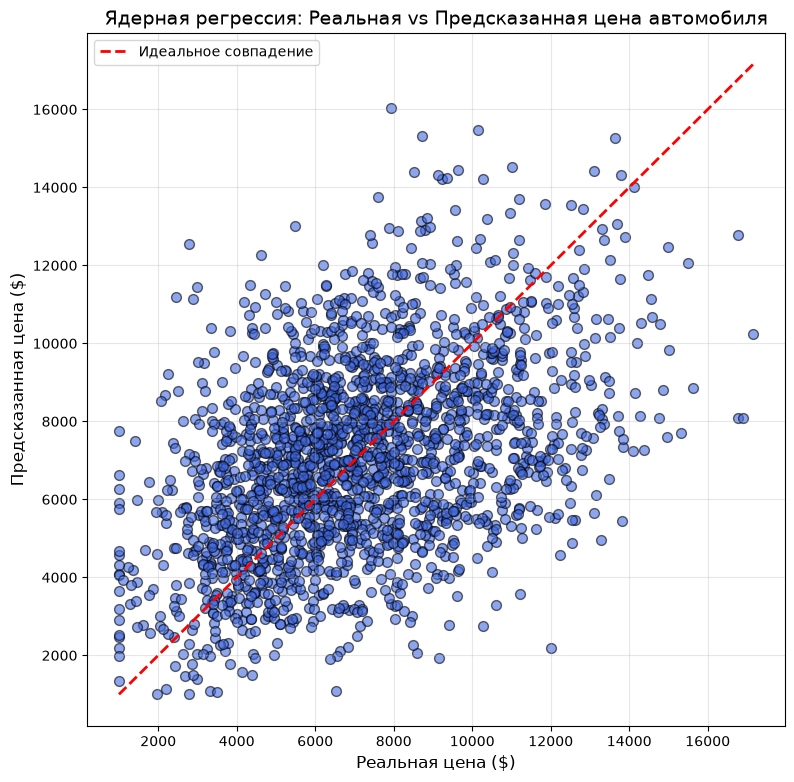

In [ ]:
plt.figure(figsize=(9, 9))

plt.scatter(y_test, y_pred_nw, alpha=0.6, color="royalblue", edgecolor="k", s=50)

max_val = max(y_test.max(), y_pred_nw.max())
min_val = min(y_test.min(), y_pred_nw.min())

plt.plot(
    [min_val, max_val], [min_val, max_val], "r--", lw=2, label="Идеальное совпадение"
)

plt.title("Ядерная регрессия: Реальная vs Предсказанная цена автомобиля", fontsize=14)
plt.xlabel("Реальная цена ($)", fontsize=12)
plt.ylabel("Предсказанная цена ($)", fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Построили график сравнения реальной и предсказанной цены.